# # ETF Cluster Evaluation — accuracy per experiment (real data)

Companion to `train_cluster.py`, the real-data counterpart of T2TSionnaSim's
`ETF_eval_master.ipynb`. Each **experiment** (1 … 13) is one physical
deployment / room scan, and plays the role the 3-D `room` plays in the sim notebook.

What it does:

1. Loads a `train_cluster.py` checkpoint + its `_config.json`.
2. Reads the **exact** train/val partition the checkpoint was trained on from the
   `<run_stem>_split.csv` that `train_cluster.py` saves next to it (sample identity
   plus the CSV row numbers behind every sample), and shows what went into val.
3. Runs inference on the val split and reports overall metrics.
4. **Breaks every metric down by experiment** — tables, bar charts, per-wall
   heatmaps, error CDFs, error-vs-distance curves, run-to-run consistency and
   top-view wall plots.
5. Separates **seen** experiments (in the train split) from **unseen** ones
   (held out with `--val_experiments`). That split is the "new room" test.

> With a random split (the default), every experiment appears on both sides. The
> runs of one sub-cluster can land on both sides too, and K-of-N sub-clusters
> from one experiment share most of their tags, so those numbers are
> in-distribution. Train with `--val_experiments` for a genuine transfer number.

In [1]:
import glob
import importlib
import json
import os
import sys

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# ── Locate multitag_ml_training/ (this notebook's folder) so the CWD doesn't matter ───────
HERE = os.path.abspath(".")
while HERE != "/" and not os.path.isfile(os.path.join(HERE, "train_cluster.py")):
    cand = os.path.join(HERE, "multitag_ml_training")
    if os.path.isfile(os.path.join(cand, "train_cluster.py")):
        HERE = cand
        break
    HERE = os.path.dirname(HERE)
assert os.path.isfile(os.path.join(HERE, "train_cluster.py")), \
    "Could not locate multitag_ml_training/train_cluster.py — launch this notebook from inside RFImaging/"
if HERE not in sys.path:
    sys.path.insert(0, HERE)

import train_cluster as _tc
importlib.reload(_tc)
from train_cluster import load_for_args, load_split, split_indices, preprocess, SUB_KEYS
from MLScripts.models.transformer import TagPairTransformer   # path set up by train_cluster

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
print("ml dir    :", HERE)
print("T2T_ROOT   :", _tc.T2T_ROOT)

ml dir    : /Users/manavjeet/git/RFImaging/multitag_ml_training
T2T_ROOT   : /Users/manavjeet/git/T2TSionnaSim


## Configuration

Everything tunable lives in this one cell. Leave `CHECKPOINT_PATH = None` for the
newest checkpoint in `SAVED_DIR`; the dataset always comes from that
checkpoint's `_config.json`, unless `DATASET_PATH` overrides it.

**`EVAL_EXPERIMENTS` picks which experiments the whole notebook reports on.**
Every table and chart downstream follows it.

In [2]:
CHECKPOINT_PATH = "/Users/manavjeet/git/RFImaging/multitag_ml_training/Saved/ETF_cluster_K10_45slots_alpha_poslocal_d128_l6_ep30_s42_1012225659.pth"
DATASET_PATH    = "/Users/manavjeet/git/RFImaging/multitag/cluster_features_K10_P1.csv"      # None → the CSV the checkpoint was trained on
SAVED_DIR       = os.path.join(HERE, "Saved")

# EVAL_EXPERIMENTS filters the VALIDATION side; None → every experiment in val.
# EVAL_TRAIN_EXPERIMENTS filters the train-side reference; None → all in train.
EVAL_EXPERIMENTS       = None
EVAL_TRAIN_EXPERIMENTS = None

EVAL_TRAIN_SPLIT = True     # also score the train split (seen-vs-unseen / overfit gap)
VIZ_EXPERIMENTS  = None     # experiments for the top-view wall plots; None → all of EVAL_EXPERIMENTS
VIZ_LIMIT        = 12       # sub-clusters drawn per experiment in those plots
OTHER_DATASET    = None     # another cluster_features_*.csv with the same K, for a transfer test

if CHECKPOINT_PATH is None:
    _cands = sorted(
        (p for p in glob.glob(os.path.join(SAVED_DIR, "ETF_cluster_*.pth"))
         if os.path.exists(p.replace(".pth", "_config.json"))),
        key=os.path.getmtime,
    )
    if not _cands:
        raise FileNotFoundError(
            f"No checkpoint in {SAVED_DIR}. Train one with\n"
            f"  python multitag_ml_training/train_cluster.py --dataset multitag/cluster_features_K10_P1.csv"
        )
    for _p in _cands[-5:]:
        print(f"  {'->' if _p == _cands[-1] else '  '} {os.path.basename(_p)}")
    CHECKPOINT_PATH = _cands[-1]

config_path = CHECKPOINT_PATH.replace(".pth", "_config.json")
print(f"\nCheckpoint : {CHECKPOINT_PATH}")
print(f"Config     : {config_path}")


Checkpoint : /Users/manavjeet/git/RFImaging/multitag_ml_training/Saved/ETF_cluster_K10_45slots_alpha_poslocal_d128_l6_ep30_s42_1012225659.pth
Config     : /Users/manavjeet/git/RFImaging/multitag_ml_training/Saved/ETF_cluster_K10_45slots_alpha_poslocal_d128_l6_ep30_s42_1012225659_config.json


## Load config and model

In [3]:
with open(config_path) as f:
    run_cfg = json.load(f)
print(json.dumps(
    {k: v for k, v in run_cfg.items() if k not in ("train_losses", "val_losses")},
    indent=2,
))

train_args = dict(run_cfg["args"])
if DATASET_PATH is not None:
    if os.path.realpath(DATASET_PATH) != os.path.realpath(train_args["dataset"]):
        print(f"\n[warn] evaluating on {DATASET_PATH}, but the checkpoint was trained on "
              f"{train_args['dataset']} — the split below is NOT the training split.")
    train_args["dataset"] = DATASET_PATH
DATASET_PATH = train_args["dataset"]
assert os.path.exists(DATASET_PATH), f"Dataset not found: {DATASET_PATH}"

{
  "run_stem": "ETF_cluster_K10_45slots_alpha_poslocal_d128_l6_ep30_s42_1012225659",
  "args": {
    "dataset": "/Users/manavjeet/git/RFImaging/multitag/cluster_features_K10_P1.csv",
    "no_alpha": false,
    "include_avgv": false,
    "no_positions": false,
    "pos_frame": "local",
    "run_mode": "each",
    "experiments": null,
    "val_experiments": null,
    "test_size": 0.2,
    "split": "group",
    "d_model": 128,
    "nhead": 4,
    "num_layers": 6,
    "dim_feedforward": 512,
    "dropout": 0.1,
    "epochs": 30,
    "batch_size": 32,
    "lr": 0.002,
    "warmup_epochs": 20,
    "weight_decay": 0.01,
    "l2_lambda": 0.0001,
    "huber_delta": 0.1,
    "dist_clip": 1000.0,
    "seed": 42,
    "save_dir": "/Users/manavjeet/git/RFImaging/multitag_ml_training/Saved",
    "log_every": 10,
    "gpu": 0
  },
  "model_config": {
    "n_slots": 45,
    "feat_dim": 50,
    "d_model": 128,
    "nhead": 4,
    "num_layers": 6,
    "dim_feedforward": 512,
    "dropout": 0.1,
    "out

Device      : mps
Parameters  : 1,203,464
feat_dim    : 50   slices: {'theta': [0, 22], 'alpha': [22, 44], 'pos': [44, 50]}
Trained for : best epoch 27 / 30 total


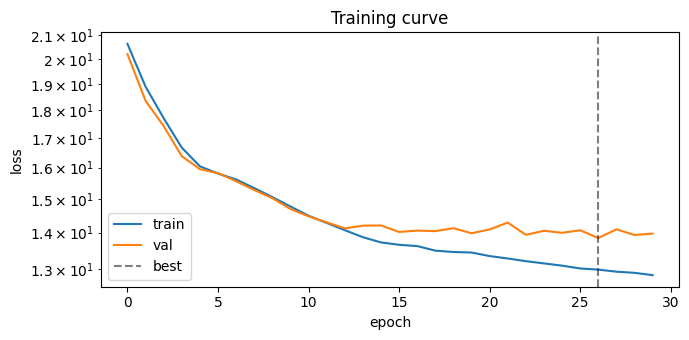

In [4]:
device = torch.device(
    "mps"  if torch.backends.mps.is_available() else
    "cuda" if torch.cuda.is_available()         else
    "cpu"
)
ckpt  = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
model = TagPairTransformer(**run_cfg["model_config"])
model.load_state_dict(ckpt["model_state_dict"])
model.to(device).eval()

print(f"Device      : {device}")
print(f"Parameters  : {sum(p.numel() for p in model.parameters()):,}")
print(f"feat_dim    : {run_cfg['model_config']['feat_dim']}   slices: {run_cfg['feature_slices']}")
print(f"Trained for : best epoch {run_cfg['best_epoch']} / {train_args['epochs']} total")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(run_cfg["train_losses"], label="train")
ax.plot(run_cfg["val_losses"], label="val")
ax.axvline(run_cfg["best_epoch"] - 1, color="k", ls="--", alpha=0.5, label="best")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.set_title("Training curve"); ax.legend(); plt.tight_layout(); plt.show()

## Load data and the saved partition

Same loader, same feature flags and same scaling as `train_cluster.main()`. The
train/val partition comes from the checkpoint's `_split.csv`. Samples are matched
by identity (experiment, combination, permutation, run), and every saved sample
has to be found. The first load of a CSV takes about a minute. After that the
parse is cached in `<csv>.parsed.npz`.

In [5]:
%%time
(X_raw, Y_dists, Y_angles, centroids, poses,
 n_pairs, n_freq, meta_df, feature_slices) = load_for_args(train_args)

assert X_raw.shape[2] == run_cfg["model_config"]["feat_dim"], (
    f"feat_dim mismatch: model expects {run_cfg['model_config']['feat_dim']}, "
    f"data has {X_raw.shape[2]} — different feature flags or K."
)

SPLIT_PATH = os.path.join(os.path.dirname(CHECKPOINT_PATH), run_cfg.get("split_file", ""))
if run_cfg.get("split_file") and os.path.isfile(SPLIT_PATH):
    split_df = pd.read_csv(SPLIT_PATH)
    train_idx, val_idx = load_split(SPLIT_PATH, meta_df)
    print(f"Split file : {SPLIT_PATH}")
    if "train_idx" in ckpt:
        assert np.array_equal(train_idx, np.sort(ckpt["train_idx"])) and \
               np.array_equal(val_idx, np.sort(ckpt["val_idx"])), \
            "split file and checkpoint disagree on the partition"
else:
    # Checkpoints older than the split file: re-derive it from the recorded args.
    split_df = None
    print("[warn] no _split.csv for this checkpoint — re-deriving the split from the seed")
    train_idx, val_idx = split_indices(meta_df, train_args["test_size"], train_args["seed"],
                                       train_args.get("val_experiments"),
                                       train_args.get("split", "group"))
split, scalers = preprocess(X_raw, Y_dists, Y_angles, feature_slices,
                            train_idx, val_idx, centroids, poses)

# The scalers refit here must equal the ones saved in the checkpoint.
for name, sc in scalers.items():
    assert np.allclose(sc.mean_, ckpt["scalers"][name]["mean"], rtol=1e-4, atol=1e-6), \
        f"scaler {name} differs from the checkpoint — the partition was not reproduced"

meta_train_all = meta_df.iloc[train_idx].reset_index(drop=True)
meta_train_all.insert(0, "sample_idx", train_idx)
meta_val_all   = meta_df.iloc[val_idx].reset_index(drop=True)
meta_val_all.insert(0, "sample_idx", val_idx)
train_exps  = sorted(meta_train_all["experiment"].unique().tolist())
val_exps    = sorted(meta_val_all["experiment"].unique().tolist())
unseen_exps = [e for e in val_exps if e not in train_exps]

_rec = (run_cfg["n_train"], run_cfg["n_val"])
print(f"train={len(train_idx)}  val={len(val_idx)}  "
      + ("(matches the checkpoint config)" if _rec == (len(train_idx), len(val_idx))
         else f"[warn] config recorded n_train={_rec[0]}, n_val={_rec[1]}"))
print(f"train experiments : {train_exps}")
print(f"val experiments   : {val_exps}")
print(f"UNSEEN experiments: {unseen_exps or 'none — all val experiments were trained on'}")

[loader] cached parse: /Users/manavjeet/git/RFImaging/multitag/cluster_features_K10_P1.parsed.npz
[loader] dropped 27 rows with NaN/inf (missed rays or missing links)
[loader] 12606 sub-clusters × 3 run(s) → 37791 samples, n_pairs=45, n_freq=22, feat_dim=50, experiments=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
Split file : /Users/manavjeet/git/RFImaging/multitag_ml_training/Saved/ETF_cluster_K10_45slots_alpha_poslocal_d128_l6_ep30_s42_1012225659_split.csv
[preprocess] train=(30231, 45, 50)  val=(7560, 45, 50)  Y_d mean=[234.4 238.9 235.1  37.9]  Y_a mean=[ 0.4 -0.6 -0.9  1.5]
train=30231  val=7560  (matches the checkpoint config)
train experiments : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
val experiments   : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
UNSEEN experiments: none — all val experiments were trained on
CPU times: user 1.58 s, sys: 252 ms, total: 1.83 s
Wall time: 1.85 s


## Validation set

What went into val, as saved at training time:

- **counts** per experiment, overall and in sub-clusters
- **sub-cluster overlap**: how many val samples have a sibling run of the same
  sub-cluster in train. Those siblings share the ground truth, so a high share
  means val is close to train.
- **where** the val sub-cluster centroids sit in each experiment, next to the
  train ones
- the first val rows with their **CSV row numbers** (`csv_rows`, 0-based data rows;
  the file line is row + 2), so you can find them in the dataset file

,train_samples,val_samples,train_subclusters,val_subclusters,val_%,val_with_train_sibling_%
experiment,,,,,,
1,147,51,49,17,25.8,0.0
2,138,57,46,19,29.2,0.0
3,165,30,55,10,15.4,0.0
4,162,36,54,12,18.2,0.0
5,162,36,54,12,18.2,0.0
6,150,30,50,10,16.7,0.0
7,144,51,48,17,26.2,0.0
8,153,45,51,15,22.7,0.0
9,159,39,53,13,19.7,0.0


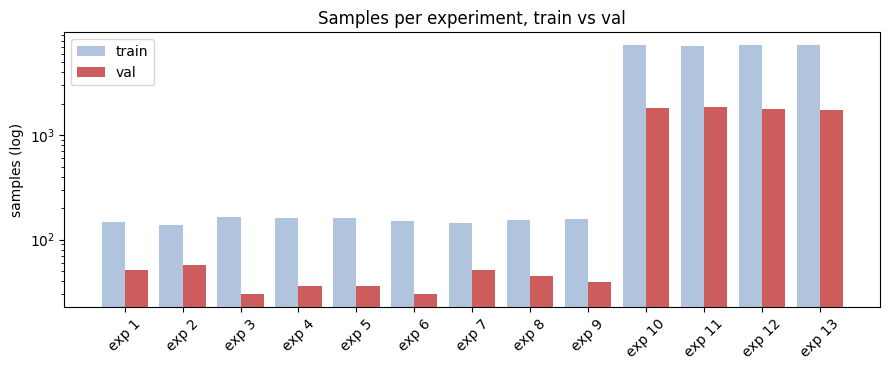

In [6]:
_sub = lambda m: m[SUB_KEYS].drop_duplicates()
_tr_subs = set(map(tuple, _sub(meta_train_all).to_numpy()))
_val_has_sib = np.array([tuple(k) in _tr_subs for k in meta_val_all[SUB_KEYS].to_numpy()])

comp = pd.DataFrame({
    "train_samples": meta_train_all["experiment"].value_counts(),
    "val_samples":   meta_val_all["experiment"].value_counts(),
    "train_subclusters": _sub(meta_train_all)["experiment"].value_counts(),
    "val_subclusters":   _sub(meta_val_all)["experiment"].value_counts(),
}).fillna(0).astype(int).sort_index()
comp["val_%"] = 100 * comp["val_samples"] / (comp["train_samples"] + comp["val_samples"])
comp["val_with_train_sibling_%"] = (
    pd.Series(_val_has_sib, index=meta_val_all["experiment"]).groupby(level=0).mean() * 100
).reindex(comp.index).fillna(0)
comp.loc["ALL"] = comp.sum()
comp.loc["ALL", "val_%"] = 100 * len(val_idx) / (len(train_idx) + len(val_idx))
comp.loc["ALL", "val_with_train_sibling_%"] = 100 * _val_has_sib.mean() if len(_val_has_sib) else 0
comp.index.name = "experiment"
display(comp.style.format({"val_%": "{:.1f}", "val_with_train_sibling_%": "{:.1f}"}
                         | {c: "{:.0f}" for c in comp.columns if c.endswith(("_samples", "_subclusters"))})
        .set_caption(f"Train / val composition  "
                     f"(split: {train_args.get('split', 'group')}"
                     + (f", val_experiments={train_args['val_experiments']}"
                        if train_args.get("val_experiments") else
                        f", test_size={train_args['test_size']}") + ")"))

fig, ax = plt.subplots(figsize=(9, 3.8))
_e = comp.index[comp.index != "ALL"]
_x = np.arange(len(_e))
ax.bar(_x - 0.2, comp.loc[_e, "train_samples"], 0.4, label="train", color="lightsteelblue")
ax.bar(_x + 0.2, comp.loc[_e, "val_samples"],   0.4, label="val",   color="indianred")
ax.set_xticks(_x, [f"exp {e}" for e in _e], rotation=45)
ax.set_yscale("log"); ax.set_ylabel("samples (log)")
ax.set_title("Samples per experiment, train vs val"); ax.legend()
plt.tight_layout(); plt.show()

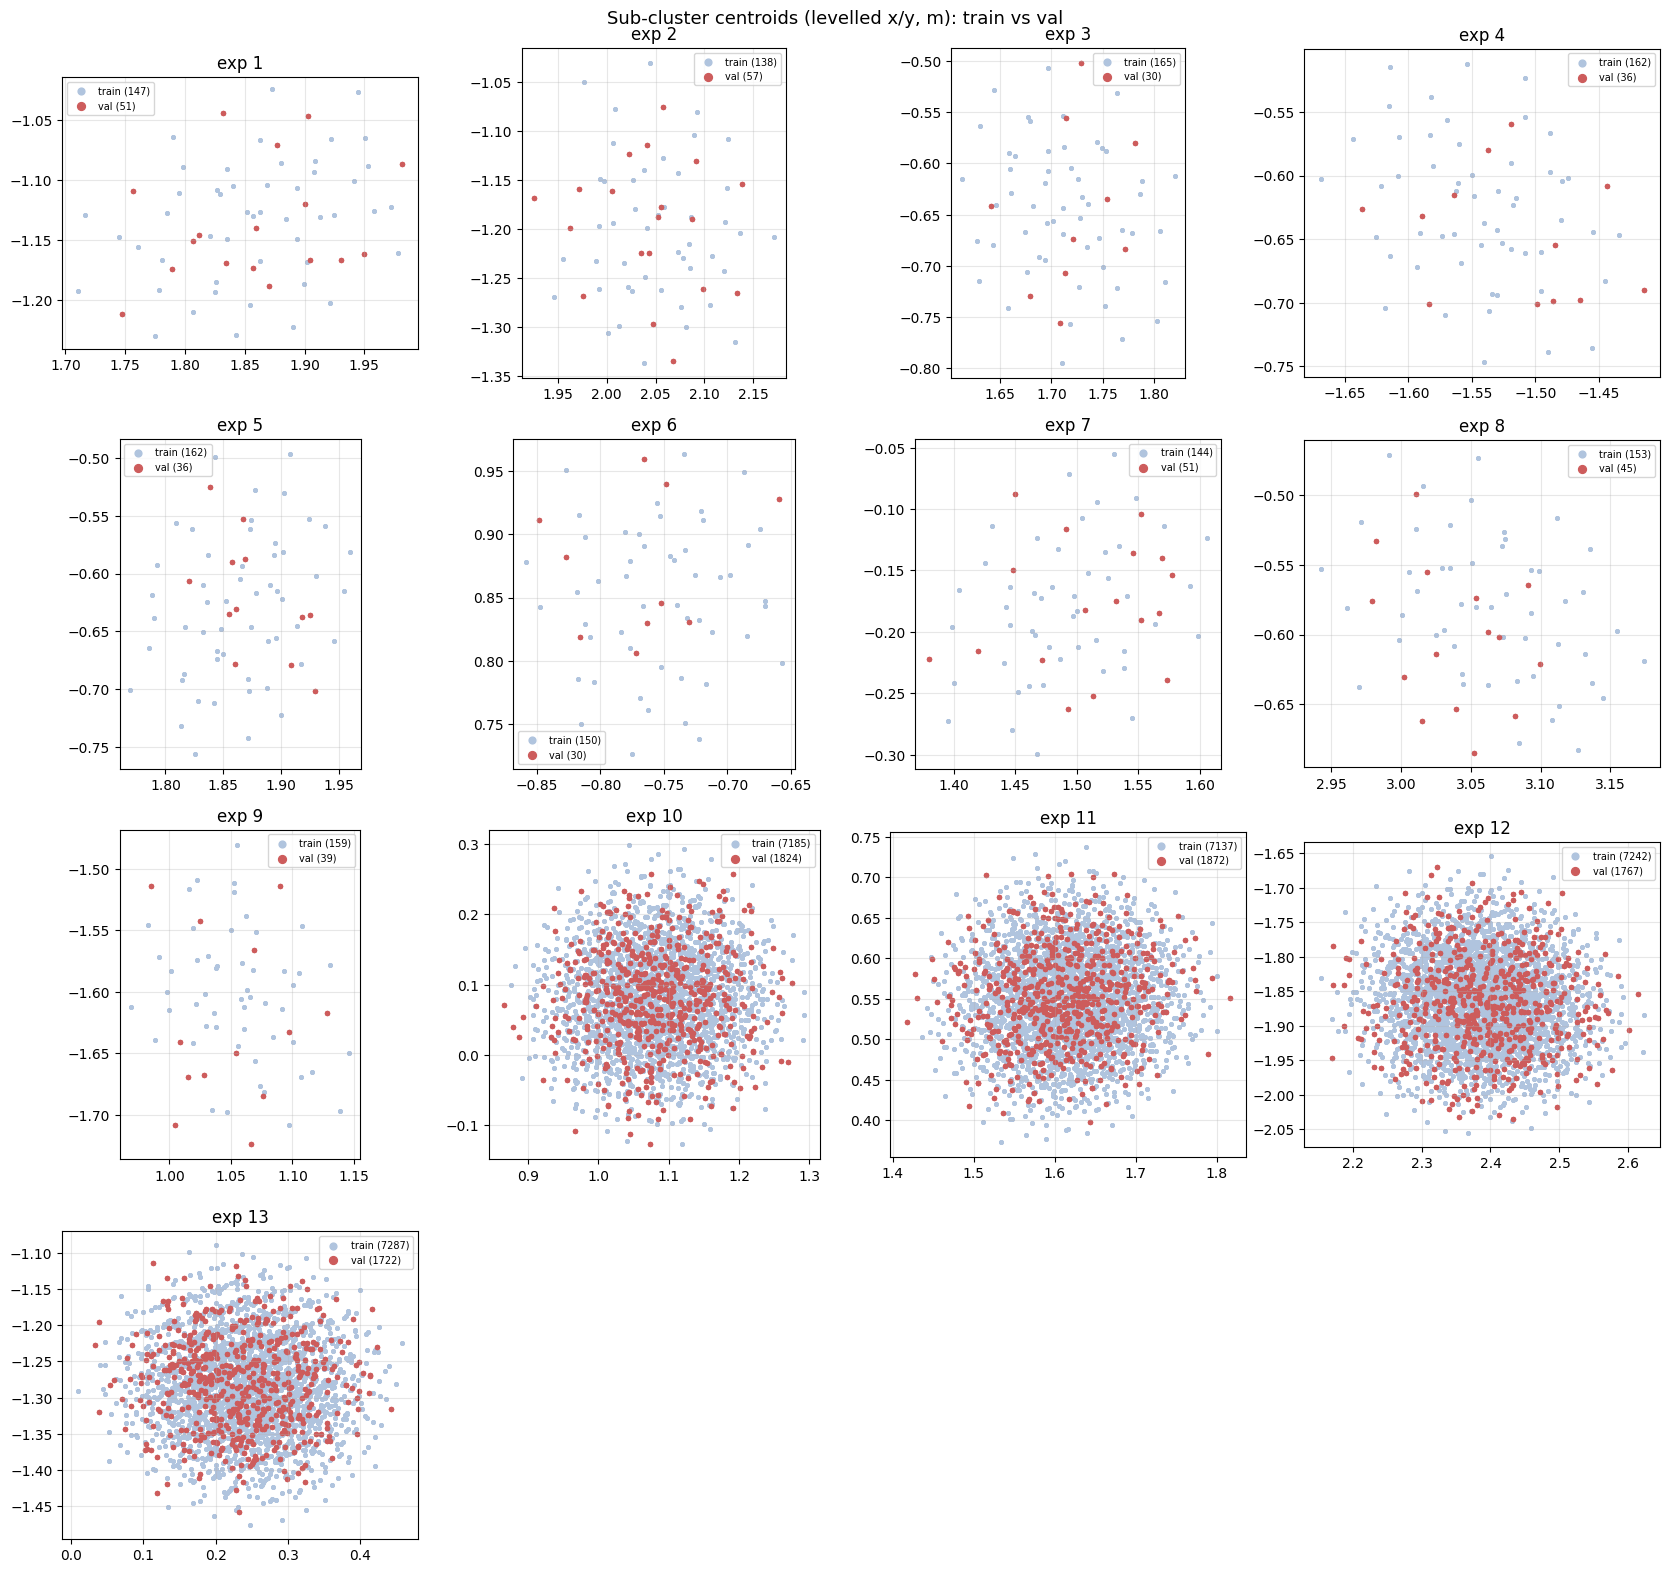

First val samples (csv_rows = 0-based data rows of the dataset CSV):


,sample_idx,experiment,combination_id,permutation_id,run,csv_rows
0,0,1,0,0,0,0;1;2;3;4;5;6;7;8;9;10;11;12;13;14;15;16;17;18...
1,1,1,0,0,1,22;23;24;25;26;27;28;29;30;31;32;33;34;35;36;3...
2,2,1,0,0,2,44;45;46;47;48;49;50;51;52;53;54;55;56;57;58;5...
3,9,1,3,0,0,198;199;200;201;202;203;204;205;206;207;208;20...
4,10,1,3,0,1,220;221;222;223;224;225;226;227;228;229;230;23...
5,11,1,3,0,2,242;243;244;245;246;247;248;249;250;251;252;25...
6,24,1,8,0,0,528;529;530;531;532;533;534;535;536;537;538;53...
7,25,1,8,0,1,550;551;552;553;554;555;556;557;558;559;560;56...
8,26,1,8,0,2,572;573;574;575;576;577;578;579;580;581;582;58...
9,42,1,14,0,0,924;925;926;927;928;929;930;931;932;933;934;93...


In [7]:
# Where the val sub-clusters sit in each experiment, next to the train ones.
_ctr_tr, _ctr_va = split["centers_train"], split["centers_val"]
_ex_tr, _ex_va = meta_train_all["experiment"].to_numpy(), meta_val_all["experiment"].to_numpy()
_all_e = sorted(set(_ex_tr) | set(_ex_va))
_nc = min(4, len(_all_e)); _nr = int(np.ceil(len(_all_e) / _nc))
fig, axes = plt.subplots(_nr, _nc, figsize=(4.2 * _nc, 4.0 * _nr), squeeze=False)
for ax, e in zip(axes.ravel(), _all_e):
    t, v = _ctr_tr[_ex_tr == e], _ctr_va[_ex_va == e]
    ax.scatter(t[:, 0], t[:, 1], s=6, color="lightsteelblue", label=f"train ({len(t)})")
    ax.scatter(v[:, 0], v[:, 1], s=8, color="indianred", label=f"val ({len(v)})")
    ax.set_title(f"exp {e}"); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.legend(fontsize=7, markerscale=2)
for ax in axes.ravel()[len(_all_e):]:
    ax.axis("off")
plt.suptitle("Sub-cluster centroids (levelled x/y, m): train vs val", fontsize=13)
plt.tight_layout(); plt.show()

print("First val samples (csv_rows = 0-based data rows of the dataset CSV):")
display(meta_val_all[["sample_idx"] + SUB_KEYS + ["run", "csv_rows"]].head(10))

## Experiment selection

Applies `EVAL_EXPERIMENTS` (val side) and `EVAL_TRAIN_EXPERIMENTS` (train side).
It only narrows which rows get scored. The partition is always the training one.
You can re-run this cell on its own.

In [8]:
def _select(requested, available, label):
    if requested is None:
        return list(available)
    unknown = [e for e in requested if e not in available]
    if unknown:
        raise ValueError(f"{label} not in this split: {unknown}\nAvailable: {list(available)}")
    return list(dict.fromkeys(requested))


exps        = _select(EVAL_EXPERIMENTS,       val_exps,   "EVAL_EXPERIMENTS")
train_sel   = _select(EVAL_TRAIN_EXPERIMENTS, train_exps, "EVAL_TRAIN_EXPERIMENTS")
seen_exps   = [e for e in exps if e in train_exps]
unseen_sel  = [e for e in exps if e not in train_exps]
IS_UNSEEN   = {e: (e not in train_exps) for e in exps}

mask_val   = meta_val_all["experiment"].isin(exps).to_numpy()
mask_train = meta_train_all["experiment"].isin(train_sel).to_numpy()

X_val_eval = split["X_val"][mask_val]
true_d     = split["Y_d_val"][mask_val]            # cm
true_a     = split["Y_a_val"][mask_val]            # deg
meta_val   = meta_val_all[mask_val].reset_index(drop=True)
gt_centers = split["centers_val"][mask_val]
gt_poses   = split["pose_val"][mask_val]

X_train_eval = split["X_train"][mask_train]
true_d_tr    = split["Y_d_train"][mask_train]
true_a_tr    = split["Y_a_train"][mask_train]
meta_train   = meta_train_all[mask_train].reset_index(drop=True)

print(f"Reporting on {len(exps)} of {len(val_exps)} val experiments: {exps}")
print(f"  seen in training : {seen_exps or 'none'}")
print(f"  UNSEEN           : {unseen_sel or 'none'}")
print("\nsamples per experiment (val / train):")
for e in exps:
    print(f"  exp {e:<4} {int((meta_val['experiment'] == e).sum()):>6} / "
          f"{int((meta_train_all['experiment'] == e).sum()):>6}"
          f"{'   [UNSEEN]' if IS_UNSEEN[e] else ''}")

Reporting on 13 of 13 val experiments: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
  seen in training : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
  UNSEEN           : none

samples per experiment (val / train):
  exp 1        51 /    147
  exp 2        57 /    138
  exp 3        30 /    165
  exp 4        36 /    162
  exp 5        36 /    162
  exp 6        30 /    150
  exp 7        51 /    144
  exp 8        45 /    153
  exp 9        39 /    159
  exp 10     1824 /   7185
  exp 11     1872 /   7137
  exp 12     1767 /   7242
  exp 13     1722 /   7287


## Inference

In [9]:
@torch.no_grad()
def predict(X: np.ndarray, batch: int = 1024):
    # Batched forward pass → (pred_dists [cm], pred_angles [deg])
    outs_d, outs_a = [], []
    for i in range(0, len(X), batch):
        xb = torch.from_numpy(np.ascontiguousarray(X[i:i + batch])).to(device)
        pd_, pa_ = model(xb, None)
        outs_d.append(pd_.cpu().numpy())
        outs_a.append(pa_.cpu().numpy())
    return np.concatenate(outs_d), np.concatenate(outs_a)


pred_d, pred_a = predict(X_val_eval)
print(f"pred_d {pred_d.shape}  pred_a {pred_a.shape}")

pred_d (7560, 4)  pred_a (7560, 4)


## Metrics

Distances in **cm**, angles in **degrees**.

| metric | meaning |
|---|---|
| `mae_dist_cm` | mean absolute error over all 4 wall distances, **unclipped** |
| `medae` / `p90` | median and 90th-percentile absolute error |
| `acc<=10/20/50cm` | fraction of wall-distance predictions within that tolerance |
| `%oor` | fraction of predictions outside the plausible window (`DIST_LIM`) |
| `baseline_cm` | MAE of a **no-input constant**: the per-wall mean of the training targets |
| `gain_cm` | `baseline_cm − mae_dist_cm`, i.e. how much the model beats that constant |
| `mae_angle_vert_deg` | angle MAE over hits on **vertical** surfaces only (`wall_vertical == 1`); the angle target is 0 elsewhere |

Read `gain_cm` first. Experiments differ a lot in room size, so raw MAE alone
can't tell a model that reads the RF signal from one that has learned the
average wall distance.

In [10]:
PLOT_MAX    = float(np.ceil(true_d.max() / 50.0) * 50.0)   # cm
DIST_LIM    = (0.0, PLOT_MAX + 100.0)                       # cm
ANGLE_LIM   = (-90.0, 90.0)
WALL_LABELS = ["N", "S", "E", "W"]
CONST_BASELINE = true_d_tr.mean(axis=0) if len(true_d_tr) else None

print(f"GT wall distance range: {true_d.min():.1f} – {true_d.max():.1f} cm  "
      f"→ PLOT_MAX={PLOT_MAX:.0f} cm, plausibility window {DIST_LIM} cm")
if CONST_BASELINE is not None:
    print(f"Constant baseline (train per-wall mean): {CONST_BASELINE.round(1)} cm")


def _vert(meta):
    return meta[[f"wall_vertical_{w}" for w in WALL_LABELS]].to_numpy().astype(bool)


def metrics_for(p_d, t_d, p_a, t_a, vert) -> dict:
    err_d = p_d - t_d
    abs_d = np.abs(err_d)
    oor   = (p_d < DIST_LIM[0]) | (p_d > DIST_LIM[1])
    abs_a = np.abs(p_a - t_a)
    m = {
        "n":             len(t_d),
        "mae_dist_cm":   float(abs_d.mean()),
        "medae_dist_cm": float(np.median(abs_d)),
        "p90_dist_cm":   float(np.percentile(abs_d, 90)),
        "rmse_dist_cm":  float(np.sqrt((err_d ** 2).mean())),
        "bias_dist_cm":  float(err_d.mean()),
        "acc<=10cm":     float((abs_d <= 10).mean()),
        "acc<=20cm":     float((abs_d <= 20).mean()),
        "acc<=50cm":     float((abs_d <= 50).mean()),
        "%oor":          float(100.0 * oor.mean()),
        "gt_dist_cm":    float(t_d.mean()),
        "mae_angle_deg": float(abs_a.mean()),
        "p90_angle_deg": float(np.percentile(abs_a, 90)),
        "mae_angle_vert_deg": float(abs_a[vert].mean()) if vert.any() else np.nan,
    }
    if CONST_BASELINE is not None:
        m["baseline_cm"] = float(np.abs(t_d - CONST_BASELINE).mean())
        m["gain_cm"]     = m["baseline_cm"] - m["mae_dist_cm"]
    for i, w in enumerate(WALL_LABELS):
        m[f"mae_{w}_cm"] = float(abs_d[:, i].mean())
    return m


def per_exp_table(p_d, t_d, p_a, t_a, meta, order=None) -> pd.DataFrame:
    col  = meta["experiment"].to_numpy()
    vert = _vert(meta)
    rows = {}
    for e in (order if order is not None else sorted(np.unique(col))):
        s = col == e
        if s.any():
            rows[e] = metrics_for(p_d[s], t_d[s], p_a[s], t_a[s], vert[s])
    rows["ALL"] = metrics_for(p_d, t_d, p_a, t_a, vert)
    return pd.DataFrame(rows).T


overall = metrics_for(pred_d, true_d, pred_a, true_a, _vert(meta_val))
print("── Overall (val split) ───────────────────────────────")
print(f"MAE dist   : {overall['mae_dist_cm']:.2f} cm  ({overall['mae_dist_cm']/100:.3f} m)")
print(f"Median dist: {overall['medae_dist_cm']:.2f} cm     p90: {overall['p90_dist_cm']:.2f} cm")
print(f"RMSE dist  : {overall['rmse_dist_cm']:.2f} cm     out-of-range: {overall['%oor']:.2f} %")
print(f"within 20cm: {overall['acc<=20cm']*100:.1f} %      within 50cm: {overall['acc<=50cm']*100:.1f} %")
print(f"MAE angle  : {overall['mae_angle_deg']:.2f} deg   (vertical hits only: "
      f"{overall['mae_angle_vert_deg']:.2f} deg)")
if "baseline_cm" in overall:
    print(f"\nno-input constant baseline : {overall['baseline_cm']:.2f} cm")
    print(f"model gains over it        : {overall['gain_cm']:+.2f} cm "
          f"({overall['gain_cm'] / overall['baseline_cm'] * 100:+.1f} %)")
    if overall["gain_cm"] < 0.1 * overall["baseline_cm"]:
        print("  [!] under 10% better than ignoring the inputs: the model is mostly "
              "predicting the average wall distance.")

GT wall distance range: 0.0 – 892.4 cm  → PLOT_MAX=900 cm, plausibility window (0.0, 1000.0) cm
Constant baseline (train per-wall mean): [234.4 238.9 235.1  37.9] cm
── Overall (val split) ───────────────────────────────
MAE dist   : 110.58 cm  (1.106 m)
Median dist: 48.41 cm     p90: 333.34 cm
RMSE dist  : 182.52 cm     out-of-range: 0.18 %
within 20cm: 33.6 %      within 50cm: 50.6 %
MAE angle  : 21.35 deg   (vertical hits only: 22.24 deg)

no-input constant baseline : 142.05 cm
model gains over it        : +31.47 cm (+22.2 %)


### Per-experiment accuracy (val split)

In [11]:
exp_tbl = per_exp_table(pred_d, true_d, pred_a, true_a, meta_val, order=exps)
exp_tbl["unseen"] = [IS_UNSEEN.get(e, np.nan) for e in exp_tbl.index]

_cols = ["n", "unseen", "mae_dist_cm", "baseline_cm", "gain_cm", "medae_dist_cm",
         "p90_dist_cm", "rmse_dist_cm", "bias_dist_cm",
         "acc<=10cm", "acc<=20cm", "acc<=50cm", "%oor", "gt_dist_cm",
         "mae_angle_deg", "mae_angle_vert_deg", "p90_angle_deg"]
_cols = [c for c in _cols if c in exp_tbl.columns]

_fmt = {c: "{:.2f}" for c in _cols if not c.startswith(("acc", "n", "unseen"))}
_fmt |= {c: "{:.1%}" for c in _cols if c.startswith("acc")}
_fmt |= {"n": "{:.0f}", "unseen": lambda v: "" if pd.isna(v) else ("YES" if v else "-")}
if "gain_cm" in _cols:
    _fmt["gain_cm"] = "{:+.2f}"

_sty = (exp_tbl[_cols].style.format(_fmt)
        .background_gradient(subset=["mae_dist_cm"], cmap="RdYlGn_r")
        .set_caption("Val-split accuracy per experiment  (unseen = not in the train split; "
                     "gain_cm = how much the model beats a no-input constant)"))
if "gain_cm" in _cols:
    _sty = _sty.background_gradient(subset=["gain_cm"], cmap="RdYlGn")
display(_sty)

,n,unseen,mae_dist_cm,baseline_cm,gain_cm,medae_dist_cm,p90_dist_cm,rmse_dist_cm,bias_dist_cm,acc<=10cm,acc<=20cm,acc<=50cm,%oor,gt_dist_cm,mae_angle_deg,mae_angle_vert_deg,p90_angle_deg
1,51,-,136.38,145.34,+8.95,70.74,378.61,208.69,-25.40,14.7%,21.1%,37.7%,0.00,185.69,29.56,29.56,57.13
2,57,-,116.72,140.93,+24.21,91.62,260.64,165.49,-16.17,13.2%,22.4%,43.0%,0.88,212.46,24.02,26.14,62.50
3,30,-,118.46,151.98,+33.53,102.83,265.29,161.33,1.96,19.2%,29.2%,39.2%,0.00,209.24,28.04,28.42,59.40
4,36,-,100.69,154.85,+54.17,35.53,298.35,155.54,-15.21,20.8%,37.5%,54.2%,0.00,256.91,27.24,28.32,55.53
5,36,-,129.71,154.37,+24.66,88.76,313.01,187.43,-38.30,18.8%,23.6%,38.2%,0.00,204.85,22.01,22.43,43.97
6,30,-,117.00,141.67,+24.68,55.53,375.22,182.93,26.08,24.2%,30.0%,46.7%,0.00,181.86,18.79,19.26,44.79
7,51,-,164.09,165.91,+1.83,111.78,387.09,232.60,-18.62,17.2%,24.0%,39.2%,0.00,220.77,23.91,24.92,48.96
8,45,-,108.20,126.98,+18.78,49.04,301.15,174.64,58.33,24.4%,30.0%,50.6%,0.00,209.39,21.67,23.26,45.43
9,39,-,116.49,131.67,+15.19,86.53,310.76,166.92,-23.87,23.1%,28.8%,37.2%,0.00,246.61,21.01,21.73,46.27
10,1824,-,108.56,134.92,+26.36,33.63,357.32,180.92,55.70,28.5%,39.7%,58.5%,0.00,213.61,20.45,20.93,48.98


### Seen vs unseen experiments

In [12]:
def _group(sel_exps):
    m = meta_val["experiment"].isin(sel_exps).to_numpy()
    return metrics_for(pred_d[m], true_d[m], pred_a[m], true_a[m], _vert(meta_val)[m])


groups = {}
if seen_exps:
    groups["seen (in train split)"] = _group(seen_exps)
if unseen_sel:
    groups["UNSEEN (held out)"] = _group(unseen_sel)

if len(groups) == 2:
    display(pd.DataFrame(groups).T[[c for c in _cols if c != "unseen"]].style.format(
        {k: v for k, v in _fmt.items() if k != "unseen"}))
    _s = groups["seen (in train split)"]["mae_dist_cm"]
    _u = groups["UNSEEN (held out)"]["mae_dist_cm"]
    print(f"Seen experiments   : {seen_exps}  → MAE {_s:.1f} cm")
    print(f"Held-out experiments: {unseen_sel}  → MAE {_u:.1f} cm")
    print(f"Transfer penalty   : {_u - _s:+.1f} cm  ({(_u/_s - 1)*100:+.1f} %)")
elif unseen_sel:
    print(f"Every selected experiment is UNSEEN: {unseen_sel}  → pooled MAE "
          f"{groups['UNSEEN (held out)']['mae_dist_cm']:.1f} cm")
    print("The train-split section below gives the in-distribution reference.")
else:
    print(f"Every selected experiment was in training: {seen_exps}")
    print("These are in-distribution numbers. Retrain with --val_experiments to measure transfer.")

Every selected experiment was in training: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
These are in-distribution numbers. Retrain with --val_experiments to measure transfer.


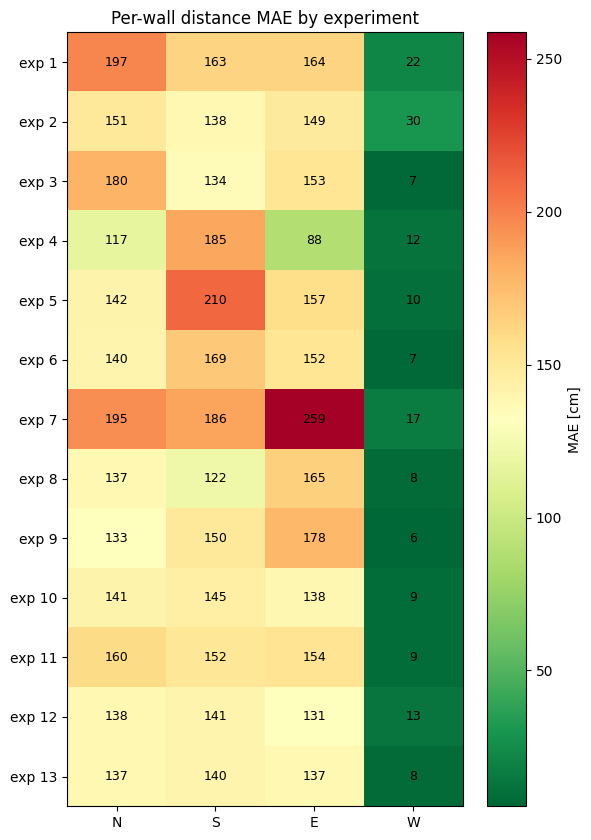

In [13]:
# Per-wall MAE — experiments × {N,S,E,W}
wall_cols = [f"mae_{w}_cm" for w in WALL_LABELS]
wall_mat  = exp_tbl.loc[exps, wall_cols].astype(float)

fig, ax = plt.subplots(figsize=(6, 0.5 * len(wall_mat) + 2))
im = ax.imshow(wall_mat.values, cmap="RdYlGn_r", aspect="auto")
ax.set_xticks(range(4), WALL_LABELS)
ax.set_yticks(range(len(wall_mat)), [f"exp {e}" for e in wall_mat.index])
for i in range(wall_mat.shape[0]):
    for j in range(wall_mat.shape[1]):
        ax.text(j, i, f"{wall_mat.values[i, j]:.0f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="MAE [cm]")
ax.set_title("Per-wall distance MAE by experiment")
plt.tight_layout(); plt.show()

### Ranking chart

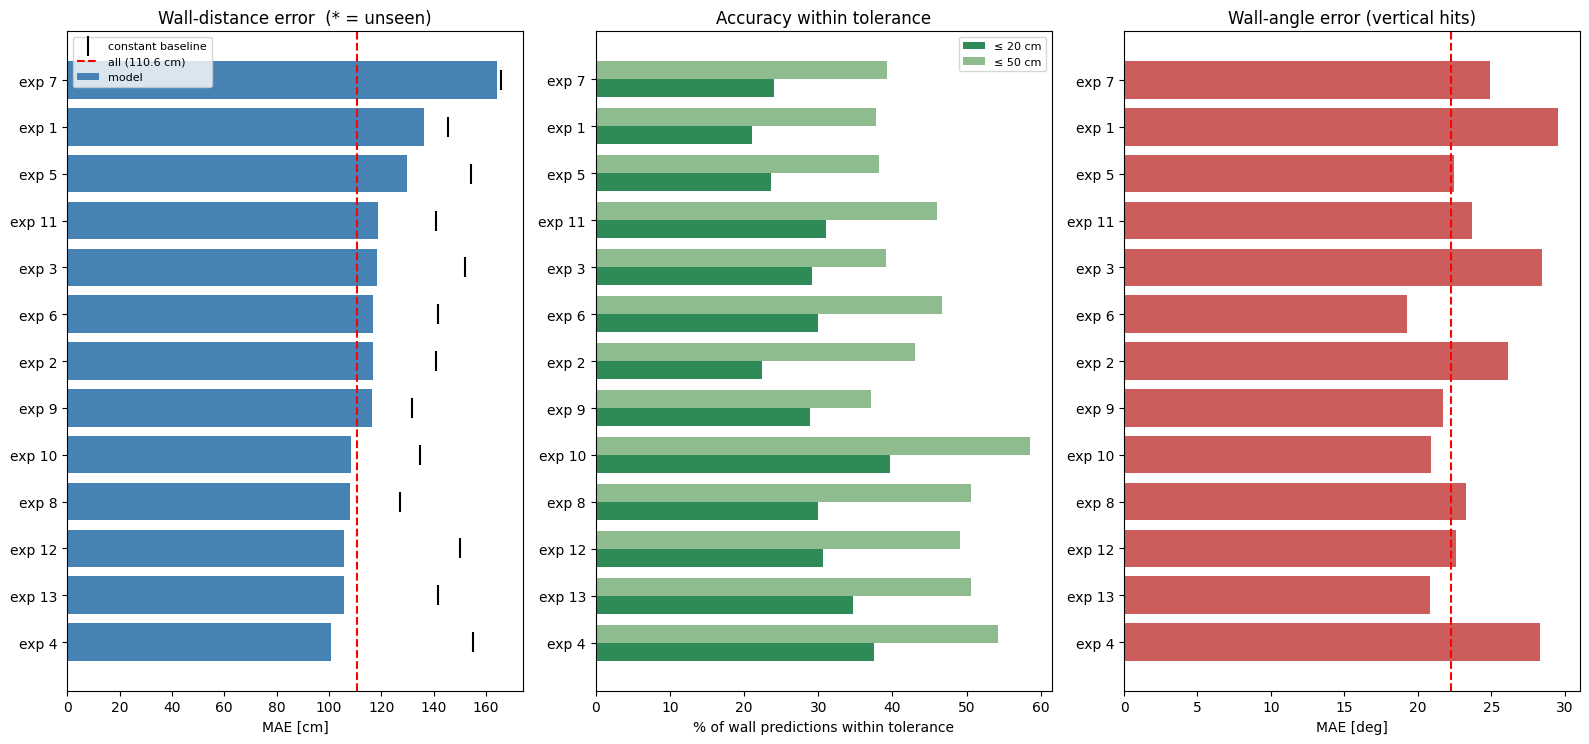

In [14]:
plot_tbl = exp_tbl.drop(index="ALL").sort_values("mae_dist_cm")
labels   = [f"exp {e}" + (" *" if IS_UNSEEN[e] else "") for e in plot_tbl.index]
fig, axes = plt.subplots(1, 3, figsize=(16, 0.35 * len(plot_tbl) + 3))

ax = axes[0]
ax.barh(labels, plot_tbl["mae_dist_cm"], color="steelblue", label="model")
if "baseline_cm" in plot_tbl:
    ax.scatter(plot_tbl["baseline_cm"], labels, marker="|", s=200, color="k",
               label="constant baseline", zorder=5)
ax.axvline(exp_tbl.loc["ALL", "mae_dist_cm"], color="red", ls="--",
           label=f"all ({exp_tbl.loc['ALL','mae_dist_cm']:.1f} cm)")
ax.set_xlabel("MAE [cm]"); ax.set_title("Wall-distance error  (* = unseen)")
ax.legend(fontsize=8)

ax = axes[1]
w = 0.38
ypos = np.arange(len(plot_tbl))
ax.barh(ypos - w/2, plot_tbl["acc<=20cm"] * 100, height=w, label="≤ 20 cm", color="seagreen")
ax.barh(ypos + w/2, plot_tbl["acc<=50cm"] * 100, height=w, label="≤ 50 cm", color="darkseagreen")
ax.set_yticks(ypos, labels)
ax.set_xlabel("% of wall predictions within tolerance"); ax.set_title("Accuracy within tolerance")
ax.legend(fontsize=8)

ax = axes[2]
ax.barh(labels, plot_tbl["mae_angle_vert_deg"], color="indianred")
ax.axvline(exp_tbl.loc["ALL", "mae_angle_vert_deg"], color="red", ls="--")
ax.set_xlabel("MAE [deg]"); ax.set_title("Wall-angle error (vertical hits)")
plt.tight_layout(); plt.show()

### Prediction vs ground truth, per experiment

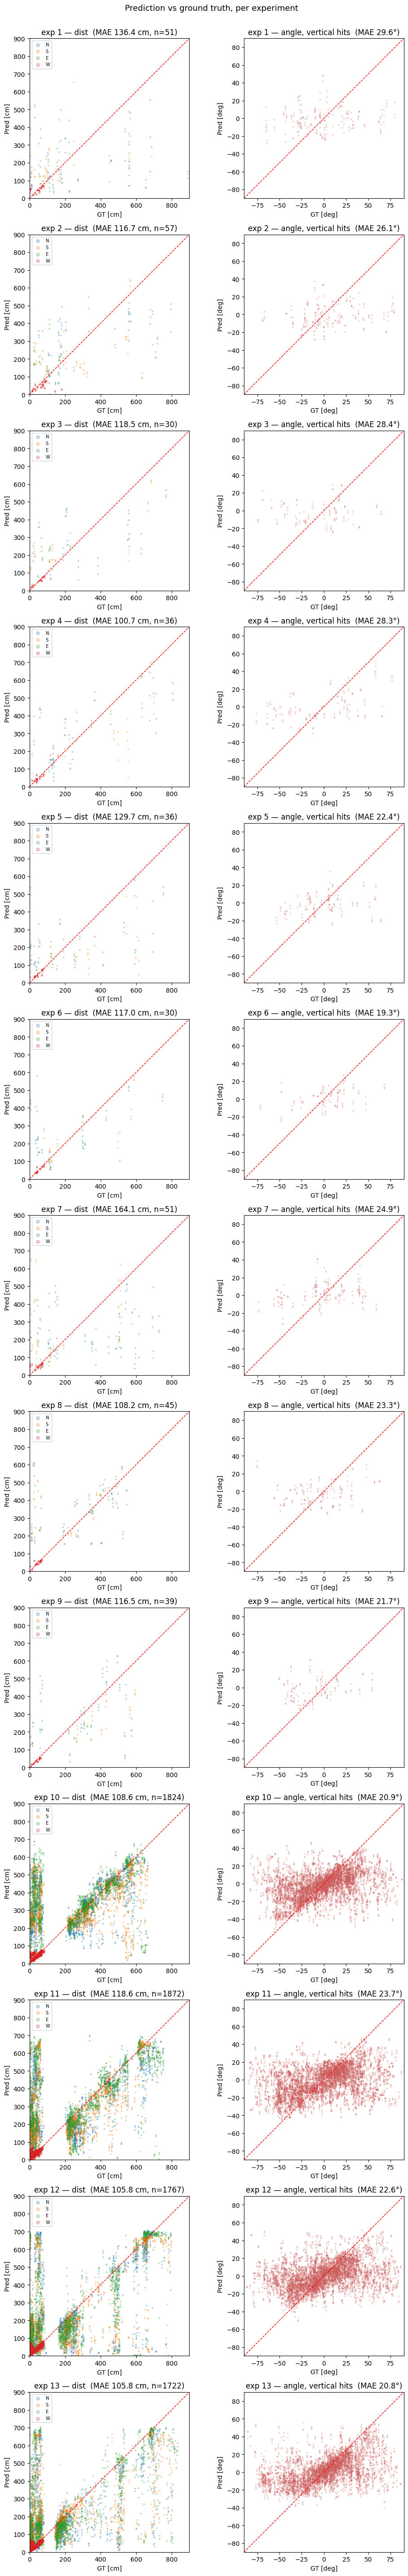

In [15]:
fig, axes = plt.subplots(len(exps), 2, figsize=(10, 4.4 * len(exps)), squeeze=False)
lim_d = (0, PLOT_MAX)
for ri, e in enumerate(exps):
    sel = meta_val["experiment"].to_numpy() == e
    ax = axes[ri][0]
    for i, wl in enumerate(WALL_LABELS):
        ax.scatter(true_d[sel, i], np.clip(pred_d[sel, i], *lim_d), s=3, alpha=0.25, label=wl)
    ax.plot(lim_d, lim_d, "r--", lw=1)
    ax.set_xlim(lim_d); ax.set_ylim(lim_d); ax.set_aspect("equal")
    ax.set_xlabel("GT [cm]"); ax.set_ylabel("Pred [cm]")
    ax.set_title(f"exp {e} — dist  (MAE {exp_tbl.loc[e,'mae_dist_cm']:.1f} cm, "
                 f"n={int(exp_tbl.loc[e,'n'])})")
    ax.legend(fontsize=7, markerscale=3)

    ax = axes[ri][1]
    v = _vert(meta_val)[sel]
    ax.scatter(true_a[sel][v], pred_a[sel][v], s=3, alpha=0.2, color="indianred")
    ax.plot(ANGLE_LIM, ANGLE_LIM, "r--", lw=1)
    ax.set_xlim(ANGLE_LIM); ax.set_ylim(ANGLE_LIM); ax.set_aspect("equal")
    ax.set_xlabel("GT [deg]"); ax.set_ylabel("Pred [deg]")
    ax.set_title(f"exp {e} — angle, vertical hits  "
                 f"(MAE {exp_tbl.loc[e,'mae_angle_vert_deg']:.1f}°)")
plt.suptitle("Prediction vs ground truth, per experiment", y=1.001, fontsize=13)
plt.tight_layout(); plt.show()

### Error distributions and difficulty profile

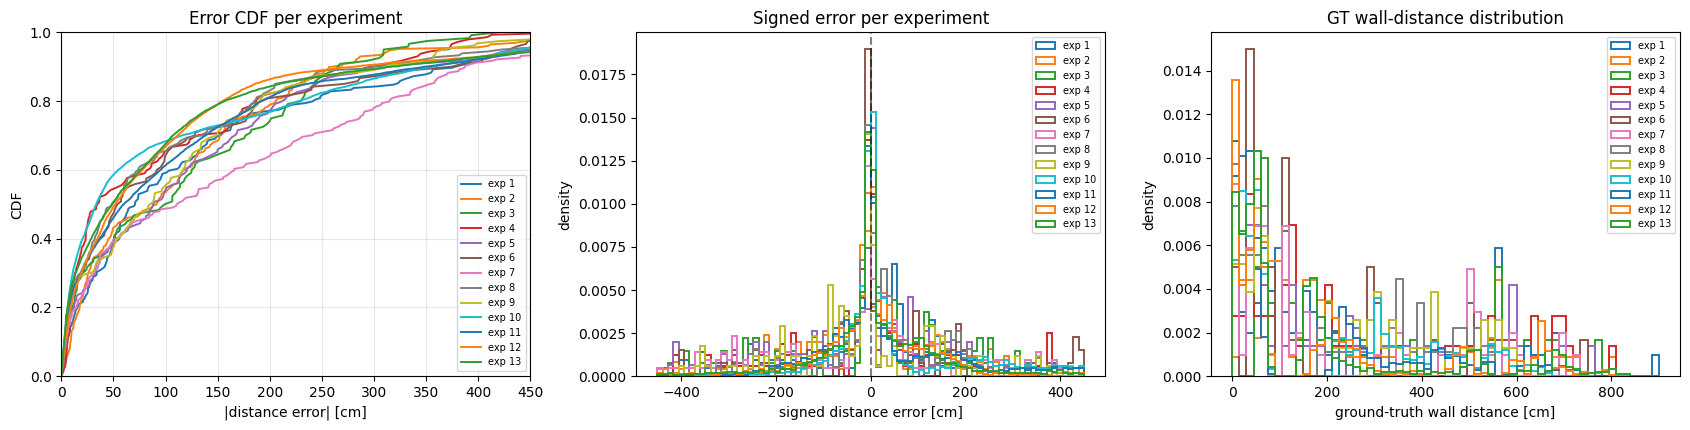

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
col = meta_val["experiment"].to_numpy()

ax = axes[0]
for e in exps:
    err = np.sort(np.abs(pred_d[col == e] - true_d[col == e]).ravel())
    ax.plot(err, np.arange(1, len(err) + 1) / len(err), lw=1.4, label=f"exp {e}")
ax.set_xlim(0, 0.5 * PLOT_MAX); ax.set_ylim(0, 1)
ax.set_xlabel("|distance error| [cm]"); ax.set_ylabel("CDF")
ax.set_title("Error CDF per experiment"); ax.grid(alpha=0.3); ax.legend(fontsize=7)

ax = axes[1]
for e in exps:
    ax.hist((pred_d[col == e] - true_d[col == e]).ravel(), bins=80,
            range=(-0.5 * PLOT_MAX, 0.5 * PLOT_MAX), density=True,
            histtype="step", lw=1.4, label=f"exp {e}")
ax.axvline(0, color="k", ls="--", alpha=0.5)
ax.set_xlabel("signed distance error [cm]"); ax.set_ylabel("density")
ax.set_title("Signed error per experiment"); ax.legend(fontsize=7)

ax = axes[2]
for e in exps:
    ax.hist(true_d[col == e].ravel(), bins=60, range=(0, PLOT_MAX), density=True,
            histtype="step", lw=1.4, label=f"exp {e}")
ax.set_xlabel("ground-truth wall distance [cm]"); ax.set_ylabel("density")
ax.set_title("GT wall-distance distribution"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

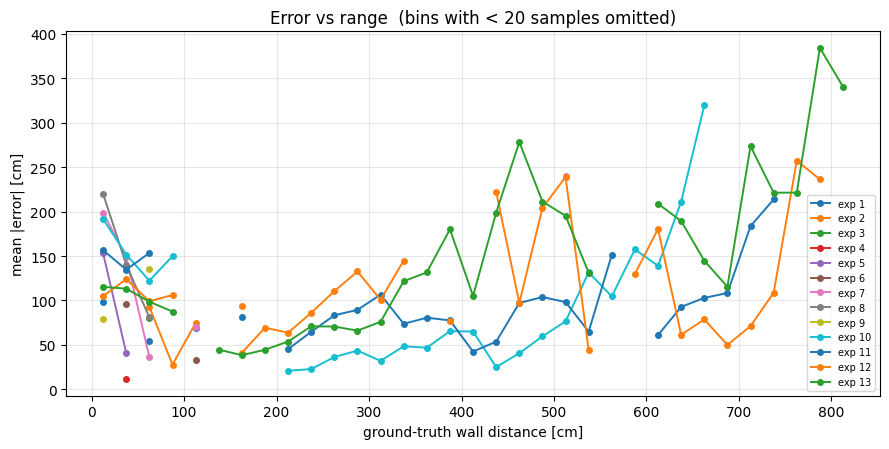

In [17]:
# Error vs ground-truth distance, per experiment
BIN_EDGES = np.arange(0, PLOT_MAX + 1, 25)
centers   = 0.5 * (BIN_EDGES[:-1] + BIN_EDGES[1:])

fig, ax = plt.subplots(figsize=(9, 4.6))
for e in exps:
    gt   = true_d[col == e].ravel()
    err  = np.abs(pred_d[col == e] - true_d[col == e]).ravel()
    bidx = np.digitize(gt, BIN_EDGES) - 1
    means = [err[bidx == b].mean() if (bidx == b).sum() >= 20 else np.nan
             for b in range(len(centers))]
    ax.plot(centers, means, marker="o", ms=4, lw=1.4, label=f"exp {e}")
ax.set_xlabel("ground-truth wall distance [cm]"); ax.set_ylabel("mean |error| [cm]")
ax.set_title("Error vs range  (bins with < 20 samples omitted)")
ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## Run-to-run consistency

Each sub-cluster was measured in several runs that share one ground truth. The
spread of the predictions across those runs shows how sensitive the model is to
measurement noise, separately from how accurate it is. Skipped for
`--run_mode mean` checkpoints, which have one sample per sub-cluster.

In [18]:
if train_args.get("run_mode", "each") == "each":
    _df = meta_val[SUB_KEYS].copy()
    for i, wl in enumerate(WALL_LABELS):
        _df[f"pred_{wl}"] = pred_d[:, i]
        _df[f"err_{wl}"]  = np.abs(pred_d[:, i] - true_d[:, i])
    _g = _df.groupby(SUB_KEYS)
    spread = _g[[f"pred_{wl}" for wl in WALL_LABELS]].std(ddof=0)
    _err   = _g[[f"err_{wl}" for wl in WALL_LABELS]].mean()
    cons = pd.DataFrame({
        "n_subclusters":   _g.size().groupby(level=0).size(),
        "run_std_cm":      spread.mean(axis=1).groupby(level=0).mean(),
        "mae_cm":          _err.mean(axis=1).groupby(level=0).mean(),
    })
    cons["std/mae"] = cons["run_std_cm"] / cons["mae_cm"]
    cons.index.name = "experiment"
    display(cons.style.format({"n_subclusters": "{:.0f}", "run_std_cm": "{:.2f}",
                               "mae_cm": "{:.2f}", "std/mae": "{:.2f}"})
            .set_caption("Mean per-wall std of the prediction across runs of one sub-cluster"))
else:
    print("run_mode=mean — one sample per sub-cluster, nothing to compare.")

,n_subclusters,run_std_cm,mae_cm,std/mae
experiment,,,,
1,17,34.08,136.38,0.25
2,19,23.71,116.72,0.20
3,10,15.95,118.46,0.13
4,12,25.46,100.69,0.25
5,12,26.25,129.71,0.20
6,10,22.91,117.00,0.20
7,17,31.62,164.09,0.19
8,15,13.65,108.20,0.13
9,13,17.08,116.49,0.15


## Train-split accuracy, per experiment

For an experiment that appears on both sides, the train↔val gap is the usual
overfitting check. With `--val_experiments` the sides are disjoint, so the train
experiments serve as the in-distribution reference. Set `EVAL_TRAIN_SPLIT = False`
to skip this section.

,n,mae_dist_cm,baseline_cm,gain_cm,medae_dist_cm,p90_dist_cm,rmse_dist_cm,bias_dist_cm,acc<=10cm,acc<=20cm,acc<=50cm,%oor,gt_dist_cm,mae_angle_deg,mae_angle_vert_deg,p90_angle_deg
1,147,134.61,160.81,+26.20,69.55,402.42,208.19,-26.00,15.8%,23.5%,40.0%,0.00,177.22,28.39,28.86,63.06
2,138,121.15,165.78,+44.62,60.80,345.94,185.82,-36.06,12.7%,24.5%,46.9%,0.00,249.61,23.44,24.77,52.19
3,165,98.53,153.84,+55.31,50.82,270.10,155.08,4.99,23.5%,33.9%,49.5%,0.00,215.07,22.09,22.17,50.86
4,162,95.42,144.44,+49.02,51.17,256.09,140.71,-2.43,16.0%,28.4%,49.5%,0.00,235.95,22.66,22.97,52.09
5,162,110.15,155.12,+44.97,70.53,277.90,158.88,9.65,15.9%,24.7%,40.1%,0.00,173.86,22.72,23.68,46.21
6,150,93.19,144.25,+51.05,60.22,229.49,133.85,15.11,19.0%,27.0%,44.5%,0.00,172.55,24.55,25.40,55.30
7,144,112.71,150.70,+37.99,62.63,292.89,168.61,-8.15,21.7%,30.0%,43.6%,0.35,184.42,22.51,23.73,44.55
8,153,119.44,135.21,+15.77,73.89,337.19,178.35,37.32,22.2%,30.6%,44.1%,0.00,216.24,22.82,23.96,48.35
9,159,106.50,141.73,+35.24,81.25,240.22,152.55,13.07,21.5%,26.9%,39.6%,0.00,212.97,24.85,25.77,46.34
10,7185,100.43,135.17,+34.74,31.54,330.87,169.52,57.39,28.9%,40.5%,60.3%,0.00,211.68,20.63,21.07,49.34


,n_train,n_val,mae_train_cm,mae_val_cm,gap_cm,gap_%
1,147,51,134.61,136.38,+1.77,+1.3%
2,138,57,121.15,116.72,-4.43,-3.7%
3,165,30,98.53,118.46,+19.93,+20.2%
4,162,36,95.42,100.69,+5.27,+5.5%
5,162,36,110.15,129.71,+19.56,+17.8%
6,150,30,93.19,117.00,+23.80,+25.5%
7,144,51,112.71,164.09,+51.38,+45.6%
8,153,45,119.44,108.20,-11.24,-9.4%
9,159,39,106.50,116.49,+9.99,+9.4%
10,7185,1824,100.43,108.56,+8.13,+8.1%


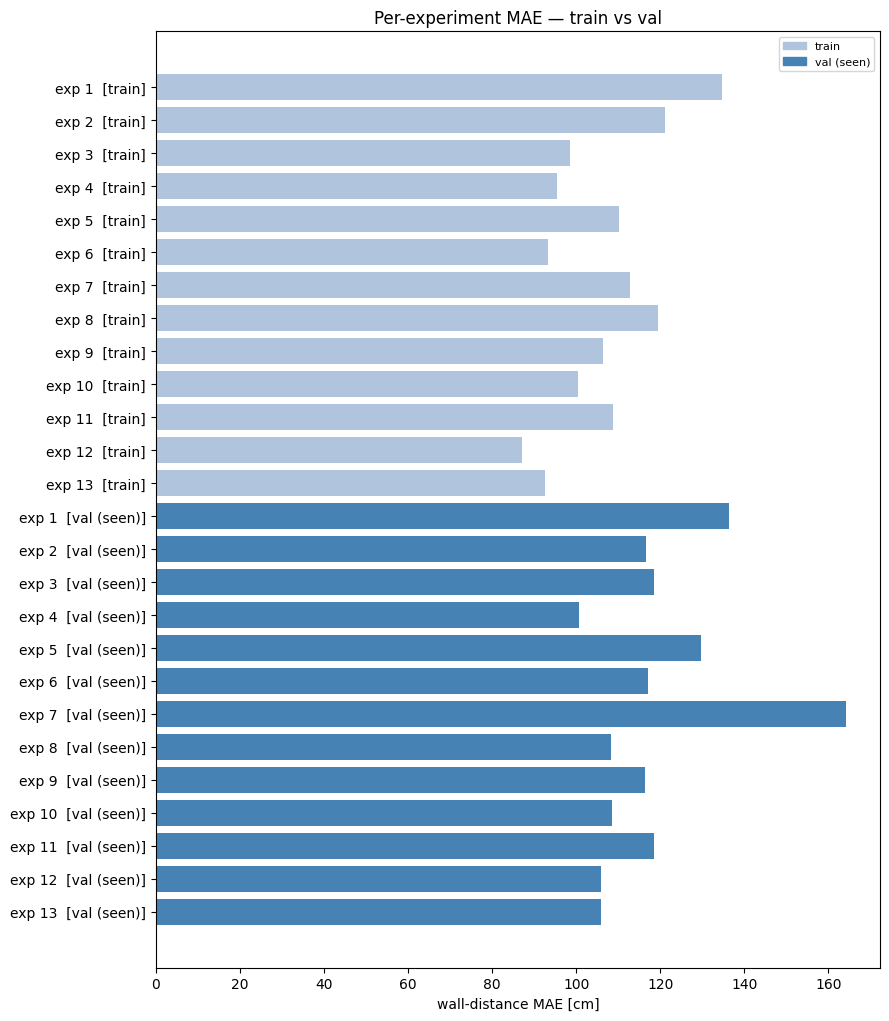

In [19]:
if EVAL_TRAIN_SPLIT:
    pred_d_tr, pred_a_tr = predict(X_train_eval)
    train_tbl = per_exp_table(pred_d_tr, true_d_tr, pred_a_tr, true_a_tr,
                              meta_train, order=train_sel)
    display(train_tbl[[c for c in _cols if c != "unseen"]].style.format(
        {k: v for k, v in _fmt.items() if k != "unseen"}
    ).set_caption("Train-split accuracy per experiment"))

    both = [e for e in exps if e in train_tbl.index]
    if both:
        gap = pd.DataFrame({
            "n_train":      train_tbl.loc[both, "n"],
            "n_val":        exp_tbl.loc[both, "n"],
            "mae_train_cm": train_tbl.loc[both, "mae_dist_cm"],
            "mae_val_cm":   exp_tbl.loc[both, "mae_dist_cm"],
        }).astype(float)
        gap["gap_cm"] = gap["mae_val_cm"] - gap["mae_train_cm"]
        gap["gap_%"]  = 100 * (gap["mae_val_cm"] / gap["mae_train_cm"] - 1)
        display(gap.style.format({"n_train": "{:.0f}", "n_val": "{:.0f}",
                                  "mae_train_cm": "{:.2f}", "mae_val_cm": "{:.2f}",
                                  "gap_cm": "{:+.2f}", "gap_%": "{:+.1f}%"})
                .background_gradient(subset=["gap_cm"], cmap="RdYlGn_r"))
    else:
        gap = None
        print("No experiment appears in both splits, so there's no per-experiment gap to report.")

    bars = ([(e, train_tbl.loc[e, "mae_dist_cm"], "train") for e in train_sel]
            + [(e, exp_tbl.loc[e, "mae_dist_cm"],
                "val (UNSEEN)" if IS_UNSEEN[e] else "val (seen)") for e in exps])
    bar_df = pd.DataFrame(bars, columns=["exp", "mae_cm", "kind"])
    colors = {"train": "lightsteelblue", "val (seen)": "steelblue", "val (UNSEEN)": "indianred"}
    fig, ax = plt.subplots(figsize=(9, 0.32 * len(bar_df) + 2))
    ypos = np.arange(len(bar_df))
    ax.barh(ypos, bar_df["mae_cm"], color=[colors[k] for k in bar_df["kind"]])
    ax.set_yticks(ypos, [f"exp {e}  [{k}]" for e, k in zip(bar_df["exp"], bar_df["kind"])])
    ax.invert_yaxis(); ax.set_xlabel("wall-distance MAE [cm]")
    ax.set_title("Per-experiment MAE — train vs val")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=k)
                       for k, c in colors.items() if (bar_df["kind"] == k).any()], fontsize=8)
    plt.tight_layout(); plt.show()
else:
    train_tbl = gap = None
    print("skipped")

## Range-matched comparison

This reweights each experiment's errors onto the pooled GT-distance histogram,
so an experiment doesn't look easy just because its walls are closer.
`range_coverage` is the share of that histogram the experiment covers. Compare
experiments with similar coverage.

In [20]:
edges  = np.arange(0, PLOT_MAX + 1, 25)
ref_w, _ = np.histogram(true_d.ravel(), bins=edges, density=True)
rows = {}
for e in exps:
    gt  = true_d[col == e].ravel()
    err = np.abs(pred_d[col == e] - true_d[col == e]).ravel()
    b   = np.digitize(gt, edges) - 1
    num = den = 0.0
    for k in range(len(ref_w)):
        m = b == k
        if m.sum() >= 20 and ref_w[k] > 0:
            num += ref_w[k] * err[m].mean()
            den += ref_w[k]
    rows[e] = {
        "mae_raw_cm":           float(err.mean()),
        "mae_range_matched_cm": float(num / den) if den else np.nan,
        "gt_mean_cm":           float(gt.mean()),
        "range_coverage":       float(den / ref_w.sum()) if ref_w.sum() else np.nan,
    }
rm = pd.DataFrame(rows).T.sort_values("mae_range_matched_cm")
rm["delta_vs_raw_cm"] = rm["mae_range_matched_cm"] - rm["mae_raw_cm"]
display(rm.style.format({"mae_raw_cm": "{:.2f}", "mae_range_matched_cm": "{:.2f}",
                         "gt_mean_cm": "{:.2f}", "delta_vs_raw_cm": "{:+.2f}",
                         "range_coverage": "{:.1%}"}))

,mae_raw_cm,mae_range_matched_cm,gt_mean_cm,range_coverage,delta_vs_raw_cm
4,100.69,11.45,256.91,18.7%,-89.24
1,136.38,79.64,185.69,39.1%,-56.74
3,118.46,79.98,209.24,15.1%,-38.47
2,116.72,89.43,212.46,19.4%,-27.29
6,117.00,94.87,181.86,19.1%,-22.13
5,129.71,99.71,204.85,39.3%,-30.00
9,116.49,102.96,246.61,35.7%,-13.53
12,105.84,109.01,185.44,95.7%,+3.17
13,105.84,114.18,164.72,97.5%,+8.35
11,118.56,122.38,188.55,91.0%,+3.82


## Wall geometry, top view, per experiment

For a few val sub-clusters per experiment, this draws the centroid, the
N/S/E/W rays (rebuilt from `pose` the same way `cluster_features.py` builds
them) and both the ground-truth hit (●) and the predicted hit (✕) on each ray.
Dotted lines join a prediction to its ground truth. Uses run 0 of each
sub-cluster.

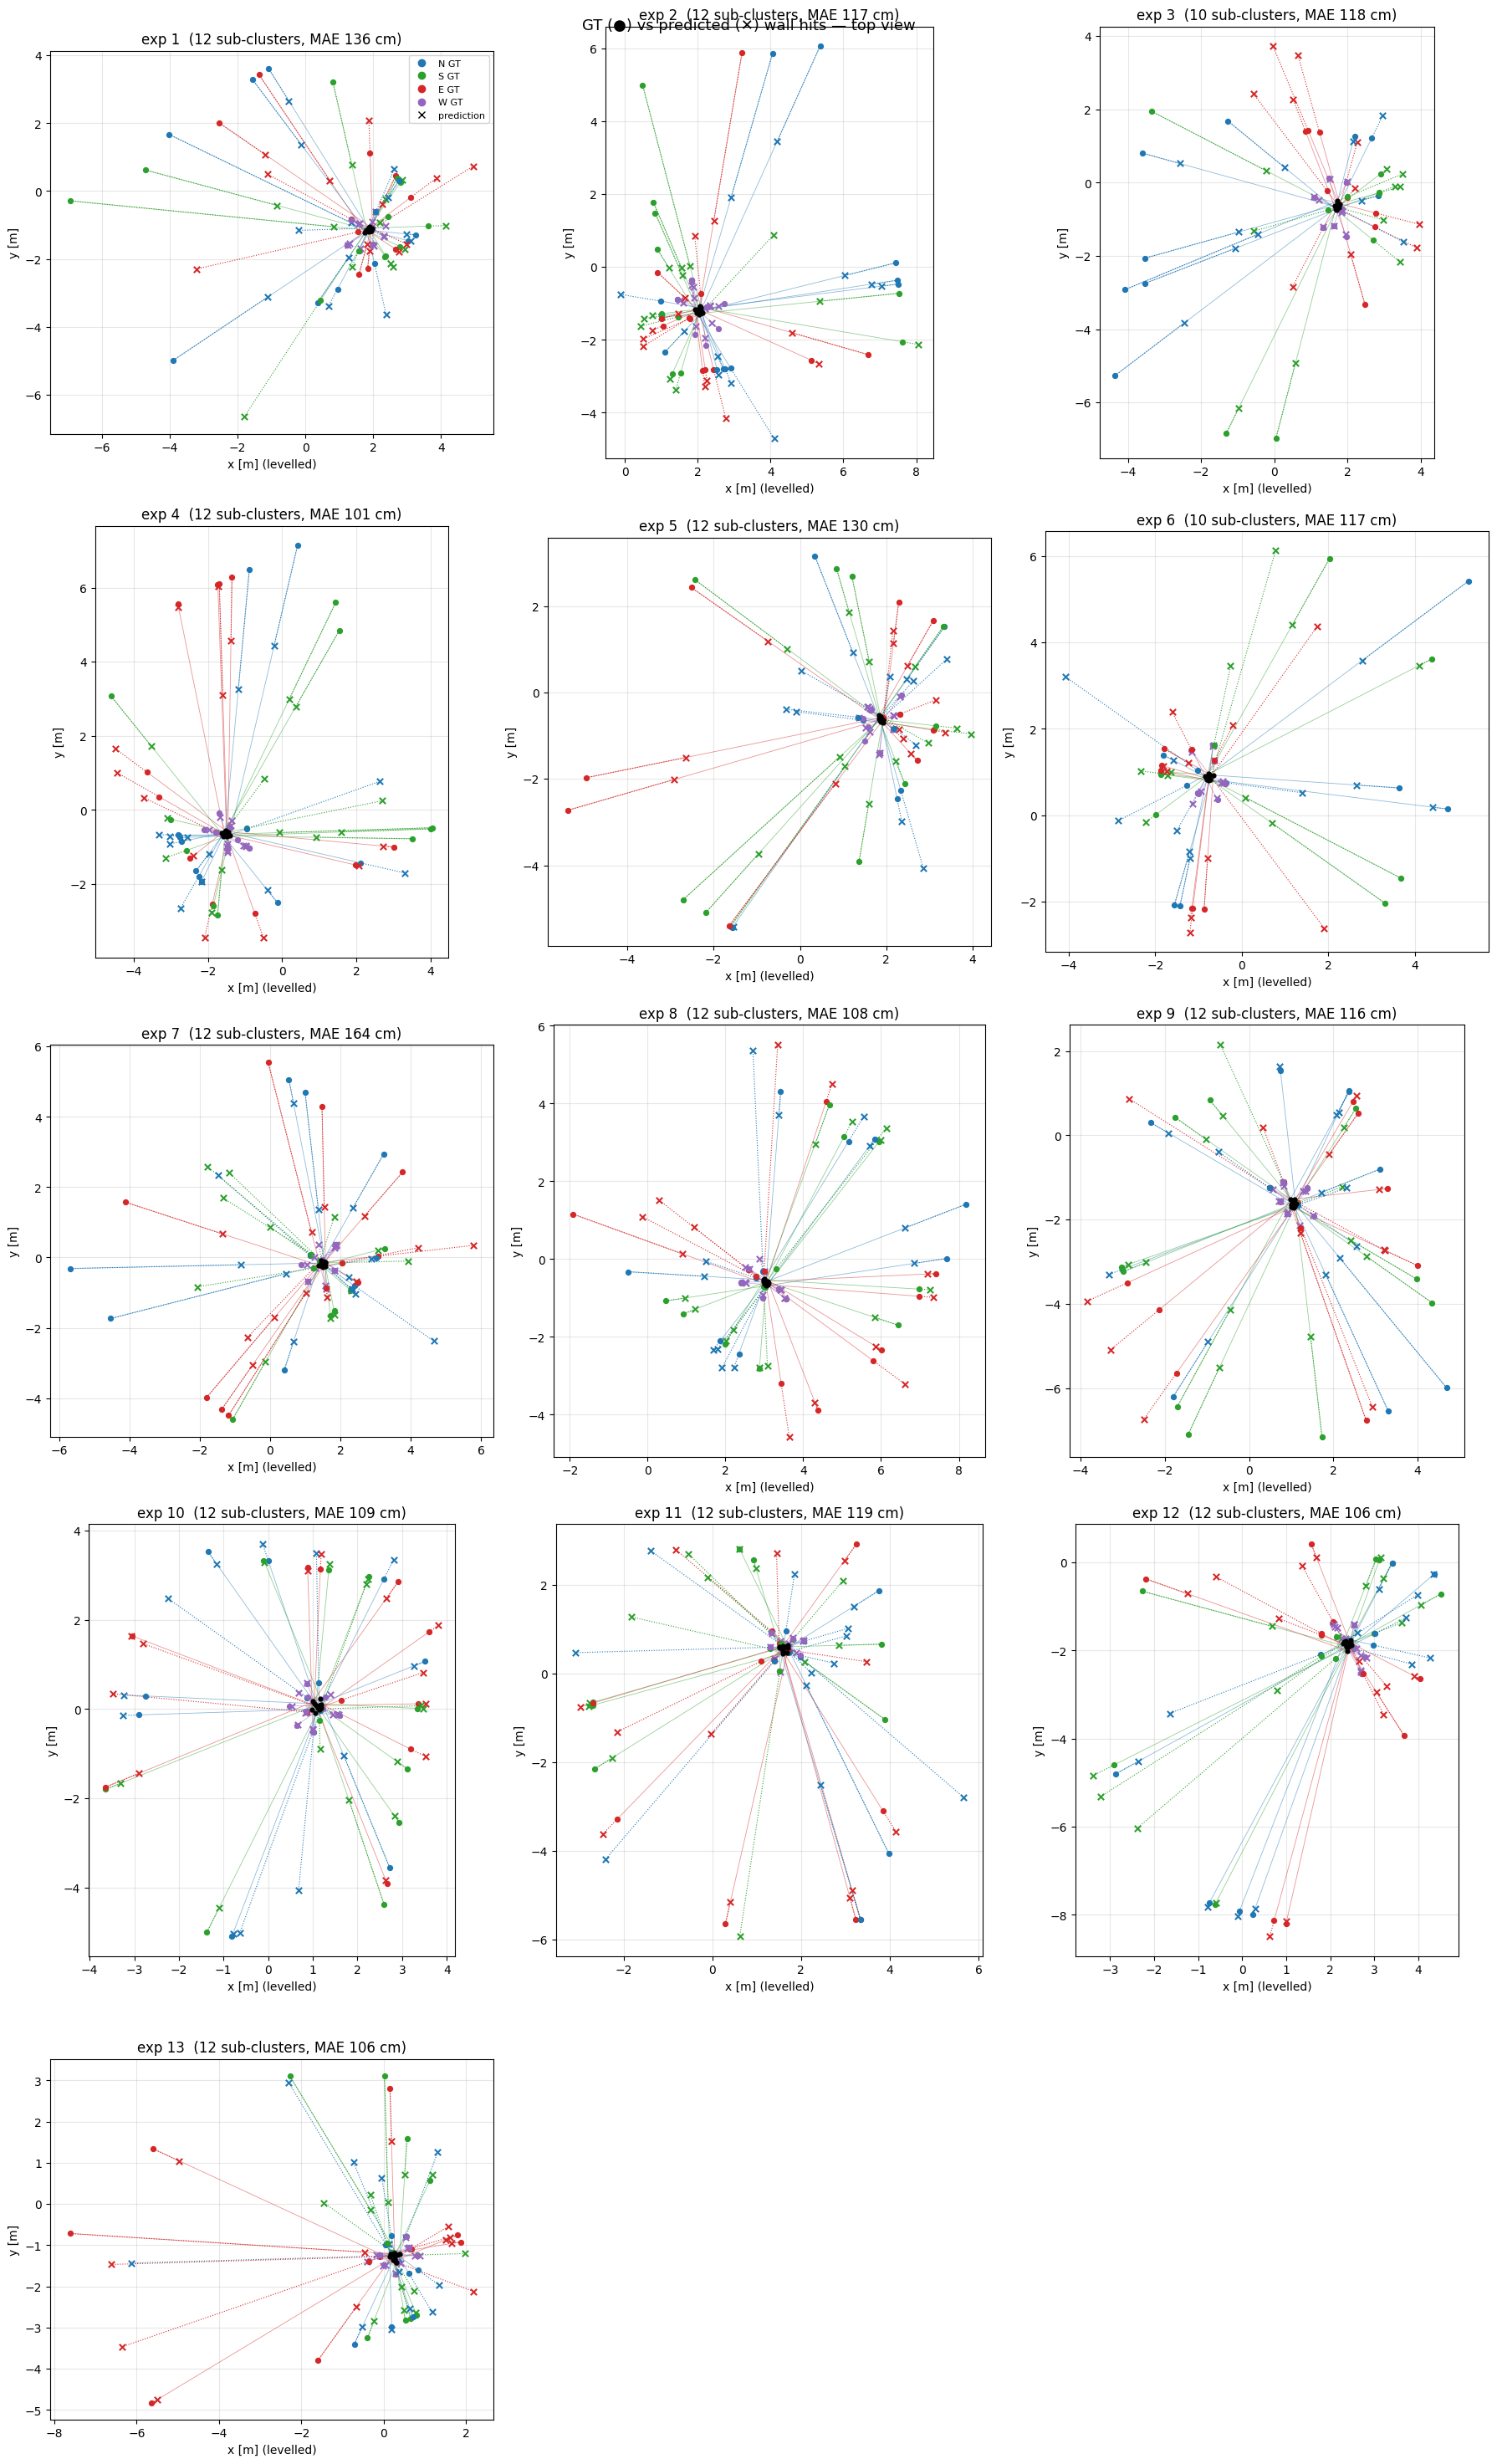

In [21]:
def ray_dirs_from_pose(q):
    # pose rotates +X onto centroid → tag 0; flatten to the ground plane like cluster_features.py
    x, y, z, w = q
    fx = np.array([1 - 2 * (y * y + z * z), 2 * (x * y + z * w), 0.0])
    fx /= np.linalg.norm(fx)
    fy = np.array([-fx[1], fx[0], 0.0])
    return np.stack([-fy, fy, -fx, fx])            # N, S, E, W


DIR_COLORS = {"N": "tab:blue", "S": "tab:green", "E": "tab:red", "W": "tab:purple"}
viz_exps = exps if VIZ_EXPERIMENTS is None else [e for e in VIZ_EXPERIMENTS if e in exps]
rng = np.random.default_rng(train_args["seed"])

ncol = min(3, len(viz_exps))
nrow = int(np.ceil(len(viz_exps) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(6 * ncol, 6 * nrow), squeeze=False)
for ax, e in zip(axes.ravel(), viz_exps):
    rows_e = np.flatnonzero((col == e) & (meta_val["run"].to_numpy() == meta_val["run"].min()))
    pick = rng.choice(rows_e, size=min(VIZ_LIMIT, len(rows_e)), replace=False)
    ax.scatter(gt_centers[col == e, 0], gt_centers[col == e, 1], s=2, color="0.85",
               zorder=1, label="all val centroids")
    for r in pick:
        c, dirs = gt_centers[r], ray_dirs_from_pose(gt_poses[r])
        ax.scatter(c[0], c[1], s=12, color="k", zorder=4)
        for i, wl in enumerate(WALL_LABELS):
            g = c + dirs[i] * true_d[r, i] / 100
            p = c + dirs[i] * np.clip(pred_d[r, i], *DIST_LIM) / 100
            ax.plot([c[0], g[0]], [c[1], g[1]], color=DIR_COLORS[wl], lw=0.6, alpha=0.5)
            ax.scatter(g[0], g[1], s=18, color=DIR_COLORS[wl], zorder=3)
            ax.scatter(p[0], p[1], s=28, marker="x", color=DIR_COLORS[wl], zorder=3)
            ax.plot([g[0], p[0]], [g[1], p[1]], color=DIR_COLORS[wl], lw=0.8, ls=":")
    ax.set_title(f"exp {e}  ({len(pick)} sub-clusters, MAE {exp_tbl.loc[e,'mae_dist_cm']:.0f} cm)"
                 + ("  [UNSEEN]" if IS_UNSEEN[e] else ""))
    ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.set_xlabel("x [m] (levelled)"); ax.set_ylabel("y [m]")
for ax in axes.ravel()[len(viz_exps):]:
    ax.axis("off")
axes[0][0].legend(handles=[plt.Line2D([], [], color=c, marker="o", ls="", label=f"{wl} GT")
                           for wl, c in DIR_COLORS.items()]
                  + [plt.Line2D([], [], color="k", marker="x", ls="", label="prediction")],
                  fontsize=8, loc="upper right")
plt.suptitle("GT (●) vs predicted (✕) wall hits — top view", fontsize=13)
plt.tight_layout(); plt.show()

## Transfer to another cluster dataset (optional)

Set `OTHER_DATASET` to another `cluster_features_*.csv` with the **same K** (for
example a different P, seed or tag set). The feature flags follow the checkpoint,
and the **training** scalers are applied, not refit.

In [22]:
if OTHER_DATASET:
    _oa = dict(train_args, dataset=OTHER_DATASET)
    (Xo, Ydo, Yao, _, _, npairs_o, _, meta_o, _) = load_for_args(_oa)
    assert Xo.shape[1:] == X_raw.shape[1:], \
        f"shape mismatch: got {Xo.shape[1:]}, model wants {X_raw.shape[1:]}"
    flat = Xo.reshape(-1, Xo.shape[2]).copy()
    for name, sl in feature_slices.items():
        flat[:, sl] = scalers[f"x_{name}"].transform(flat[:, sl])
    Xo_s = flat.reshape(Xo.shape).astype(np.float32)
    pdo, pao = predict(Xo_s)
    other_tbl = per_exp_table(pdo, Ydo, pao, Yao, meta_o)
    display(other_tbl[[c for c in _cols if c != "unseen"]].style.format(
        {k: v for k, v in _fmt.items() if k != "unseen"}
    ).set_caption(os.path.basename(OTHER_DATASET)))
else:
    print("Set OTHER_DATASET to evaluate on another cluster_features CSV.")

Set OTHER_DATASET to evaluate on another cluster_features CSV.


## Export

In [23]:
out_csv = os.path.join(SAVED_DIR, run_cfg["run_stem"] + "_perexp_eval.csv")
export = exp_tbl.copy()
if gap is not None:
    export = export.join(gap[["mae_train_cm", "gap_cm", "gap_%"]], how="left")
export.index.name = "experiment"
export.to_csv(out_csv)
print(f"Per-experiment metrics → {out_csv}")

# Per-sample val predictions, keyed by the same sample_idx / csv_rows as _split.csv
pred_csv = os.path.join(SAVED_DIR, run_cfg["run_stem"] + "_val_predictions.csv")
_p = meta_val[["sample_idx"] + SUB_KEYS + ["run", "csv_rows"]].copy()
for j, wl in enumerate(WALL_LABELS):
    _p[f"gt_dist_{wl}_cm"], _p[f"pred_dist_{wl}_cm"] = true_d[:, j], pred_d[:, j]
    _p[f"gt_angle_{wl}_deg"], _p[f"pred_angle_{wl}_deg"] = true_a[:, j], pred_a[:, j]
_p.to_csv(pred_csv, index=False)
print(f"Val predictions        → {pred_csv}")
display(export)

Per-experiment metrics → /Users/manavjeet/git/RFImaging/multitag_ml_training/Saved/ETF_cluster_K10_45slots_alpha_poslocal_d128_l6_ep30_s42_1012225659_perexp_eval.csv
Val predictions        → /Users/manavjeet/git/RFImaging/multitag_ml_training/Saved/ETF_cluster_K10_45slots_alpha_poslocal_d128_l6_ep30_s42_1012225659_val_predictions.csv


,n,mae_dist_cm,medae_dist_cm,p90_dist_cm,rmse_dist_cm,bias_dist_cm,acc<=10cm,acc<=20cm,acc<=50cm,%oor,gt_dist_cm,mae_angle_deg,p90_angle_deg,mae_angle_vert_deg,baseline_cm,gain_cm,mae_N_cm,mae_S_cm,mae_E_cm,mae_W_cm,unseen,mae_train_cm,gap_cm,gap_%
experiment,,,,,,,,,,,,,,,,,,,,,,,,
1,51.0,136.384628,70.738281,378.612488,208.685410,-25.396074,0.147059,0.210784,0.377451,0.000000,185.685043,29.562485,57.130882,29.562485,145.335495,8.950867,197.395874,162.907684,163.555603,21.679312,False,134.610352,1.774277,1.318083
2,57.0,116.717979,91.615570,260.644501,165.493881,-16.168041,0.131579,0.223684,0.429825,0.877193,212.464722,24.019125,62.498806,26.144735,140.926880,24.208900,150.699127,137.790588,148.675613,29.706614,False,121.152145,-4.434166,-3.659998
3,30.0,118.455170,102.829819,265.287811,161.325485,1.956391,0.191667,0.291667,0.391667,0.000000,209.242355,28.043676,59.401569,28.422968,151.982590,33.527420,179.538574,134.328369,152.859451,7.094321,False,98.527618,19.927551,20.225346
4,36.0,100.687607,35.530102,298.346497,155.541290,-15.205728,0.208333,0.375000,0.541667,0.000000,256.912598,27.238106,55.529602,28.319731,154.853378,54.165771,117.284027,185.451447,87.822327,12.192637,False,95.420685,5.266922,5.519686
5,36.0,129.711487,88.761391,313.011902,187.431198,-38.295921,0.187500,0.236111,0.381944,0.000000,204.847427,22.007898,43.972519,22.434965,154.372009,24.660522,141.723587,210.001251,157.347794,9.773332,False,110.151558,19.559929,17.757288
6,30.0,116.995636,55.528893,375.223663,182.934601,26.079983,0.241667,0.300000,0.466667,0.000000,181.862000,18.789055,44.788025,19.264605,141.674026,24.678391,140.225327,169.048080,152.104431,6.604741,False,93.193565,23.802071,25.540466
7,51.0,164.087418,111.777214,387.087402,232.601501,-18.620708,0.171569,0.240196,0.392157,0.000000,220.768005,23.906284,48.962795,24.923422,165.914139,1.826721,194.545883,186.341278,258.613098,16.849363,False,112.706177,51.381241,45.588665
8,45.0,108.199211,49.036087,301.149719,174.644867,58.327114,0.244444,0.300000,0.505556,0.000000,209.393127,21.672224,45.431442,23.257889,126.975044,18.775833,137.349075,122.172203,164.775711,8.499845,False,119.440285,-11.241074,-9.411459
9,39.0,116.487305,86.527824,310.763763,166.919952,-23.872381,0.230769,0.288462,0.371795,0.000000,246.611572,21.005196,46.265881,21.733873,131.674484,15.187180,132.820496,150.003174,177.515854,5.609707,False,106.496536,9.990768,9.381308
